# 01 — Exploratory Data Analysis: NBA 2025-26 Player Profiles

## Project: Positionless NBA Player Archetypes

The five traditional positions (PG, SG, SF, PF, C) were designed for a game in which guards handled the ball, wings
scored from mid-range and big men stayed near the basket. The modern NBA no longer works that way: centres run the
offense from the elbow, forwards take half their shots from three, and "point guard" describes a skill set more than a
spot on the floor. This project asks a simple question: **if we ignore the labels and group players only by what they
actually do on the court, what groups emerge, and how well do they line up with the official positions?**

The full pipeline:

1. **EDA** *(this notebook)*: understand the data and make the preprocessing decisions.
2. **Feature selection & scaling**: build a clean, non-redundant, transformed feature matrix.
3. **Dimensionality reduction**: PCA to find the main axes of playing style.
4. **Clustering**: k-means, hierarchical clustering and Gaussian Mixture Models (soft membership).
5. **Anomaly detection**: Isolation Forest / LOF to find one-of-a-kind statistical profiles.
6. **Validation**: Adjusted Rand Index between clusters and listed / actually-played positions.

## What this notebook does

No modelling happens here. The goal is to understand the data well enough to make **five decisions** that every
later step depends on:

| # | Decision | Section |
|---|---|---|
| 1 | Which players are reliable enough to include? | §2 Minutes filter |
| 2 | How should missing values be handled? | §3 Missing values |
| 3 | Which scaling / transformation suits the feature distributions? | §4 Distributions & skewness |
| 4 | Which features are redundant and should be dropped? | §5 Correlation |
| 5 | Is there evidence that listed positions under-describe player roles? | §6 Position boxplots |

## Data

Basketball-Reference season tables for the **2025-26 regular season**, merged into one row per player
(`data/nba_2025_26_players.csv`, built by `scripts/fetch_data.py`; see `data/README.md`):
per-game, per-100-possession, advanced, season totals, shot-zone shooting and play-by-play position estimates.

### Setup

Standard scientific Python stack. Two preprocessing classes are imported here because §4 compares them directly:
`StandardScaler` (centre and rescale, shape unchanged) and `PowerTransformer` (reshape toward a normal distribution).
`MIN_MP = 500` is the minutes threshold justified in §2, and `POS_ORDER` keeps every position plot ordered from the
smallest (PG) to the biggest (C) player.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler, PowerTransformer

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')

# works whether the notebook is run from the repo root or from notebooks/
DATA = Path('../data') if Path('../data').exists() else Path('data')
POS_ORDER = ['PG', 'SG', 'SF', 'PF', 'C']
MIN_MP = 500

---
## 1. Load & Inspect

**Goal.** Confirm the data loaded correctly and get an inventory: number of rows and columns, data types, and
non-null counts per column. This is the basic integrity check before any analysis: a wrong join or a parsing problem
shows up here as unexpected row counts, `object` dtypes on numeric columns, or columns that are mostly empty.

**Why it matters here.** The file is a merge of six source tables. Players traded mid-season appear in the raw tables
once per team *plus* once as a season total (`2TM`, `3TM`…). The merge keeps only the season-total row, so we
expect **exactly one row per player**. That is checked explicitly below.

**What to look for.** 582 rows with unique `player_id`s, numeric dtypes on all stat columns, and the columns whose
non-null count is below 582 (these are investigated in §3).

In [2]:
df = pd.read_csv(DATA / 'nba_2025_26_players.csv')
print('shape:', df.shape)
print('players:', df['player_id'].nunique(), '| season:', df['season'].unique())
df.info(verbose=True, show_counts=True)

shape: (582, 127)
players: 582 | season: [2026]
<class 'pandas.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 127 columns):
 #    Column                            Non-Null Count  Dtype  
---   ------                            --------------  -----  
 0    season                            582 non-null    int64  
 1    lg                                582 non-null    str    
 2    player                            582 non-null    str    
 3    player_id                         582 non-null    str    
 4    age                               582 non-null    float64
 5    team                              582 non-null    str    
 6    pos                               581 non-null    str    
 7    g                                 582 non-null    int64  
 8    gs                                582 non-null    float64
 9    mp_per_game                       582 non-null    float64
 10   fg_per_game                       582 non-null    float64
 11   fga_per_game       

**Goal.** A first look at a few rows with a small set of interpretable columns, to check the values are sensible
(minutes in the hundreds to thousands, percentages on the expected scales).

**What to look for.** Note the mixed scales: `usg_percent` and `ast_percent` are expressed as 0–100, `x3p_ar` as a
0–1 fraction, `avg_dist_fga` in feet. Features on different units are the first sign that scaling will be required
before any distance-based method (k-means, hierarchical clustering, LOF).

In [3]:
df[['player', 'team', 'pos', 'age', 'g', 'mp', 'pts_per_game', 'usg_percent',
    'ast_percent', 'trb_percent', 'x3p_ar', 'avg_dist_fga', 'bpm']].head()

,player,team,pos,age,g,mp,pts_per_game,usg_percent,ast_percent,trb_percent,x3p_ar,avg_dist_fga,bpm
0,Precious Achiuwa,SAC,C,26.0,73,1745,10.1,17.6,8.5,15.8,0.162,7.8,-1.6
1,Steven Adams,HOU,C,32.0,32,730,5.8,12.1,8.3,21.0,0.000,2.6,-0.5
2,Bam Adebayo,MIA,C,28.0,73,2365,20.1,25.0,14.1,16.1,0.349,13.3,2.0
3,Ochai Agbaji,2TM,SG,25.0,62,973,5.1,14.6,6.8,8.3,0.457,13.7,-4.0
4,Santi Aldama,MEM,PF,25.0,43,1198,14.0,20.2,15.7,13.0,0.420,14.1,1.7


**Goal.** Organise the 127 columns into groups by *what they measure*.

**Why it matters here.** Player archetypes are about **how** a player plays (role, shot selection, responsibilities),
not **how well** (efficiency, impact) or **how much** (minutes, totals). A rim-running centre who shoots 70% and one who
shoots 55% play the same *role*; mixing quality metrics into the clustering would sort players by talent rather than by
style. This grouping is the conceptual basis for feature selection in the next notebook.

**What to look for.** Which groups describe *style* (role rates, zone mix, creation) and which describe volume or
quality (per-game, totals, impact, efficiency).

In [4]:
groups = {
    'identity / context':       ['player', 'player_id', 'team', 'pos', 'age', 'g', 'gs', 'mp', 'mp_per_game'],
    'per-game box score':       [c for c in df.columns if c.endswith('_per_game') and c != 'mp_per_game'],
    'per-100-poss box score':   [c for c in df.columns if c.endswith('_per_100_poss')] + ['o_rtg', 'd_rtg'],
    'season totals':            ['fg', 'fga', 'x3p', 'x3pa', 'x2p', 'x2pa', 'ft', 'fta', 'orb', 'drb', 'trb',
                                 'ast', 'stl', 'blk', 'tov', 'pf', 'pts', 'trp_dbl'],
    'advanced: role rates':     ['usg_percent', 'ast_percent', 'tov_percent', 'orb_percent', 'drb_percent',
                                 'trb_percent', 'stl_percent', 'blk_percent', 'x3p_ar', 'f_tr'],
    'advanced: impact':         ['per', 'ts_percent', 'ows', 'dws', 'ws', 'ws_48', 'obpm', 'dbpm', 'bpm', 'vorp'],
    'shooting: zone mix':       ['avg_dist_fga'] + [c for c in df.columns if c.startswith('percent_fga_from')]
                                + ['percent_dunks_of_fga', 'percent_corner_3s_of_3pa'],
    'shooting: efficiency':     [c for c in df.columns if c.startswith('fg_percent_from')]
                                + ['fg_percent', 'x3p_percent', 'x2p_percent', 'e_fg_percent', 'ft_percent',
                                   'corner_3_point_percent'],
    'shooting: creation':       ['percent_assisted_x2p_fg', 'percent_assisted_x3p_fg'],
    'play-by-play: position %': ['pg_percent', 'sg_percent', 'sf_percent', 'pf_percent', 'c_percent'],
}
pd.DataFrame({'n_cols': {k: len(v) for k, v in groups.items()},
              'examples': {k: ', '.join(v[:4]) + (' …' if len(v) > 4 else '') for k, v in groups.items()}})

,n_cols,examples
identity / context,9,"player, player_id, team, pos …"
per-game box score,17,"fg_per_game, fga_per_game, x3p_per_game, x3pa_..."
per-100-poss box score,21,"fg_per_100_poss, fga_per_100_poss, x3p_per_100..."
season totals,18,"fg, fga, x3p, x3pa …"
advanced: role rates,10,"usg_percent, ast_percent, tov_percent, orb_per..."
advanced: impact,10,"per, ts_percent, ows, dws …"
shooting: zone mix,9,"avg_dist_fga, percent_fga_from_x2p_range, perc..."
shooting: efficiency,12,"fg_percent_from_x2p_range, fg_percent_from_x0_..."
shooting: creation,2,"percent_assisted_x2p_fg, percent_assisted_x3p_fg"
play-by-play: position %,5,"pg_percent, sg_percent, sf_percent, pf_percent …"


### Findings: Load & Inspect
- **582 players, one row each.** Traded players are represented by their season-total row, as intended.
- All stat columns are numeric; the only categoricals are `player`, `team` and `pos`.
- **`pos` (listed position) is a validation target, not an input.** It will never enter the feature matrix; it is
  used at the end to measure (via ARI) how much the data-driven clusters agree with the official labels. Using it as
  an input would make the comparison circular.
- The **role-rate**, **zone-mix** and **creation** groups are the natural archetype features. Per-game and totals are
  heavily driven by minutes (quantified in §5), and impact / efficiency metrics measure quality rather than style.
- The **play-by-play position %** columns (share of minutes spent at each slot) give a second, richer validation
  target: where coaches *actually* deployed each player, as opposed to the label on the roster.

---
## 2. The 500-Minute Filter

**Goal.** Remove players whose statistics are based on too little playing time to be trustworthy.

**Why it matters here.** Almost every feature we will cluster on is a *rate*: a percentage of possessions, of
rebounds, of shots. A rate computed over a tiny sample is dominated by chance. A player who appears in four games and
blocks two shots can post a block rate higher than any elite rim protector over a full season. If these players
stay in the data, they cause three concrete problems:

1. **Scaler distortion.** Means, standard deviations and the power-transform parameter λ are all pulled by extreme
   values, so the scaling of the *real* rotation players gets worse.
2. **Fake clusters.** k-means and GMM will happily create a "cluster" of statistical flukes.
3. **Polluted anomaly detection.** Isolation Forest and LOF would flag the small samples as the most unusual
   players, hiding the genuinely unique profiles we want to find.

**Why 500 minutes?** 500 minutes is roughly 10 minutes per game across 50 games, or about 15 full games of action.
That is a common threshold in public NBA analytics: low enough to keep rotation players, rookies and players who
missed time with injury, high enough that rate stats have stabilised. It is a judgement call; the plots below check
that it is a sensible one.

**What to look for.**
- *Left plot:* the shape of the minutes distribution and how much of the league sits below the line.
- *Right plot:* the **"funnel" shape**. If small samples are noisy, the vertical spread of BLK% should be much wider
  on the left of the line than on the right.

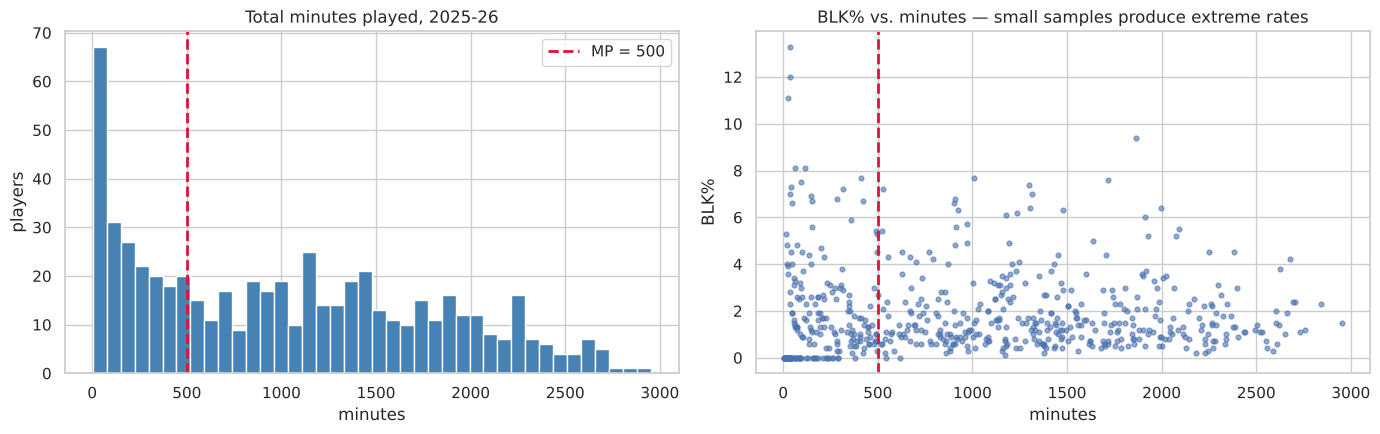

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].hist(df['mp'], bins=40, color='steelblue', edgecolor='white')
ax[0].axvline(MIN_MP, color='crimson', ls='--', lw=2, label=f'MP = {MIN_MP}')
ax[0].set(title='Total minutes played, 2025-26', xlabel='minutes', ylabel='players'); ax[0].legend()

# the classic "funnel": rate stats explode as the sample size shrinks
ax[1].scatter(df['mp'], df['blk_percent'], s=12, alpha=0.6)
ax[1].axvline(MIN_MP, color='crimson', ls='--', lw=2)
ax[1].set(title='BLK% vs. minutes — small samples produce extreme rates', xlabel='minutes', ylabel='BLK%')
plt.tight_layout(); plt.show()

**Goal.** Apply the filter and quantify its effect: how many players are removed, what the most extreme removed
values look like, and whether any position is disproportionately affected.

**What to look for.** The removed players with the most extreme block rates (are their games and minutes tiny?), and
the before/after position counts. Every position must keep enough players for the position-level comparisons in §6 and
the ARI validation at the end.

In [6]:
low = df[df['mp'] < MIN_MP]
print(f"players with mp < {MIN_MP}: {len(low)}  ({len(low)/len(df):.0%})")
print('\nexamples of extreme rates among them:')
print(low.nlargest(5, 'blk_percent')[['player', 'pos', 'g', 'mp', 'blk_percent', 'usg_percent', 'x3p_percent']]
      .to_string(index=False))

nba = df[df['mp'] >= MIN_MP].reset_index(drop=True).copy()
print(f"\nafter filter: {nba.shape[0]} players x {nba.shape[1]} columns")
pd.DataFrame({'before': df['pos'].value_counts(), 'after': nba['pos'].value_counts()}).loc[POS_ORDER].T

players with mp < 500: 203  (35%)

examples of extreme rates among them:
          player pos  g  mp  blk_percent  usg_percent  x3p_percent
    Grant Nelson  PF  4  35         13.3         21.7          NaN
  Rocco Zikarsky   C  5  36         12.0         12.6          NaN
Vladislav Goldin   C  9  24         11.1         12.6          NaN
   Dalano Banton  PG  6  62          8.1         15.3          0.0
Dereck Lively II   C  7 115          8.1         11.8          NaN

after filter: 379 players x 127 columns


pos,PG,SG,SF,PF,C
before,97,159,112,106,107
after,68,101,68,74,68


### Findings: Minutes filter
- Minutes range from 3 to about 2,950, with a large group of players at the low end. **203 players (35%) fall
  below 500 minutes** and are removed, leaving **379 players**.
- The funnel is clear: the most extreme block rates belong to players with **4–9 games and 24–115 minutes**
  (e.g. 13.3 BLK% in 35 minutes). These are noise, not rim protectors.
- Position balance survives: SG remains the largest group (101), and every other position keeps 68–74 players.
  No position is wiped out, so position-level comparisons stay meaningful.

---
## 3. Missing-Value Analysis

**Goal.** For every column with missing values, report the count and percentage, both for the full league and for
the filtered population, and visualise it with a bar chart.

**Why it matters here.** Clustering algorithms and PCA cannot handle `NaN`, so every missing value must eventually be
dropped, imputed or avoided. But the right treatment depends entirely on *why* a value is missing, so the first step
is simply to see where the gaps are and whether the minutes filter already removes most of them.

**What to look for.** Which columns are affected (if they are all *percentages*, that is a strong hint about the
mechanism), and how much the missingness shrinks after the 500-minute filter.

all 582 players         mp >= 500 (379)        
                                     missing percent         missing percent
fg_percent_from_x16_3p_range             127    21.8            26.0     6.9
fg_percent_from_x10_16_range              66    11.3             7.0     1.8
percent_assisted_x3p_fg                   66    11.3            16.0     4.2
corner_3_point_percent                    56     9.6            14.0     3.7
x3p_percent                               35     6.0            10.0     2.6
percent_corner_3s_of_3pa                  35     6.0            10.0     2.6
fg_percent_from_x3p_range                 35     6.0            10.0     2.6
ft_percent                                19     3.3             0.0     0.0
fg_percent_from_x3_10_range               14     2.4             0.0     0.0
fg_percent_from_x0_3_range                13     2.2             0.0     0.0
percent_assisted_x2p_fg                    8     1.4             0.0     0.0
x2p_percent                                3     0.5             0.0     0.0
fg_percent_from_x2p_range                  3     0.5             0.0     0.0
pos                                        1     0.2             0.0     0.0

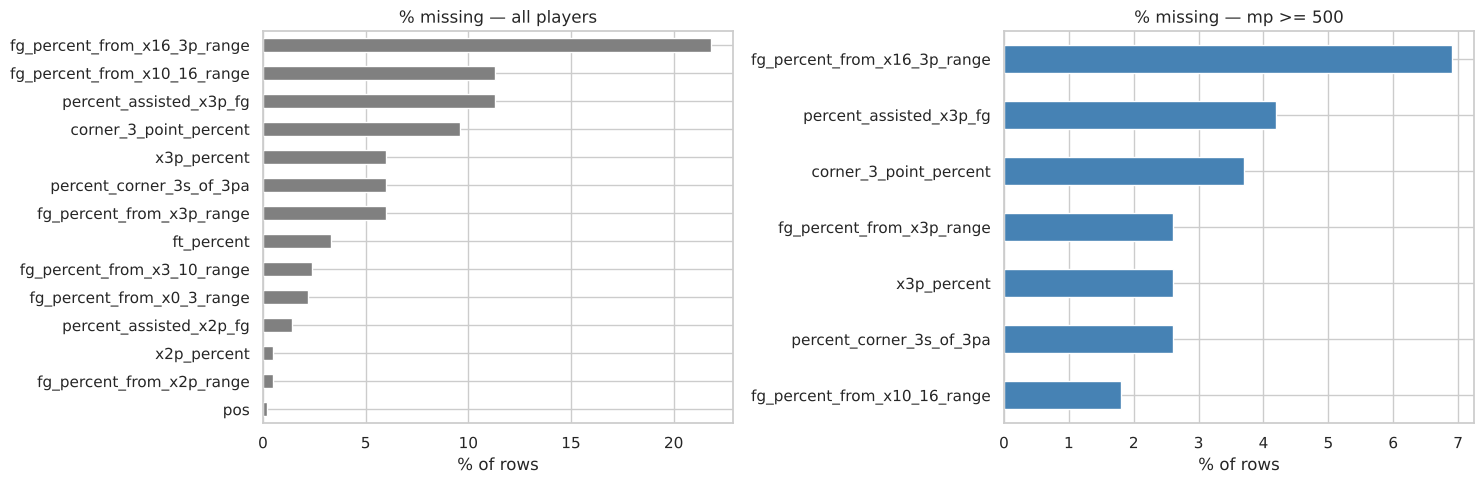

In [7]:
def missing_report(frame):
    n = frame.isna().sum()
    out = pd.DataFrame({'missing': n, 'percent': (n / len(frame) * 100).round(1)})
    return out[out['missing'] > 0].sort_values('missing', ascending=False)

miss_all, miss_nba = missing_report(df), missing_report(nba)
display(pd.concat({'all 582 players': miss_all, f'mp >= {MIN_MP} (379)': miss_nba}, axis=1).fillna(0))

fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharex=False)
miss_all['percent'].plot.barh(ax=ax[0], color='grey');      ax[0].set_title('% missing — all players')
miss_nba['percent'].plot.barh(ax=ax[1], color='steelblue'); ax[1].set_title(f'% missing — mp >= {MIN_MP}')
for a in ax: a.invert_yaxis(); a.set_xlabel('% of rows')
plt.tight_layout(); plt.show()

**Goal.** Diagnose the *mechanism* behind each missing column: is the value unobserved (it exists but was not
recorded), or is it undefined?

**Why it matters here.** Every affected column is a **shooting percentage**: makes ÷ attempts from some zone. If a
player never attempted a shot from that zone, the percentage is 0 ÷ 0, which is undefined, not unknown. Standard
imputation methods (mean/median, KNN, iterative regression) all assume the value *exists* and estimate it from other
rows. That assumption fails for undefined values, so we test the hypothesis directly: for each missing column, look up
the value of its denominator (attempts, makes or zone share) among the rows where it is missing.

**What to look for.** If the hypothesis is right, the "driver value" column should contain only 0, or very small
numbers of attempts with zero makes. Also note *which positions* the missing rows belong to.

In [8]:
checks = {
    'x3p_percent':                   ('x3pa', 'season 3PA'),
    'fg_percent_from_x3p_range':     ('x3pa', 'season 3PA'),
    'percent_corner_3s_of_3pa':      ('x3pa', 'season 3PA'),
    'corner_3_point_percent':        ('x3pa', 'season 3PA (corner 3PA = 0 also counts)'),
    'percent_assisted_x3p_fg':       ('x3p',  'season 3PM'),
    'fg_percent_from_x16_3p_range':  ('percent_fga_from_x16_3p_range', 'share of FGA from 16ft-3P'),
    'fg_percent_from_x10_16_range':  ('percent_fga_from_x10_16_range', 'share of FGA from 10-16ft'),
}
rows = []
for col, (driver, label) in checks.items():
    m = nba[col].isna()
    rows.append({'column': col, 'n_missing': int(m.sum()), 'driver': label,
                 'driver value among missing': sorted(nba.loc[m, driver].unique().round(3).tolist()),
                 'listed pos of missing': nba.loc[m, 'pos'].value_counts().to_dict()})
pd.DataFrame(rows)

,column,n_missing,driver,driver value among missing,listed pos of missing
0,x3p_percent,10,season 3PA,[0.0],{'C': 10}
1,fg_percent_from_x3p_range,10,season 3PA,[0.0],{'C': 10}
2,percent_corner_3s_of_3pa,10,season 3PA,[0.0],{'C': 10}
3,corner_3_point_percent,14,season 3PA (corner 3PA = 0 also counts),"[0.0, 1.0, 3.0, 4.0]","{'C': 12, 'PF': 2}"
4,percent_assisted_x3p_fg,16,season 3PM,[0.0],"{'C': 15, 'PF': 1}"
5,fg_percent_from_x16_3p_range,26,share of FGA from 16ft-3P,[0.0],"{'C': 10, 'PF': 8, 'SG': 5, 'SF': 3}"
6,fg_percent_from_x10_16_range,7,share of FGA from 10-16ft,[0.0],"{'PF': 3, 'C': 2, 'SG': 1, 'SF': 1}"


**Goal.** Show concretely what a standard imputation would do to the players with no three-point percentage.

**Why it matters here.** The 10 players missing `x3p_percent` are all centres who **attempted zero threes** over a
full season. Their real basketball identity is "never shoots from outside", and that is exactly the kind of signal
archetype clustering needs to preserve. The table fills the gap with the column median, the most common default, to
show what it would do.

**What to look for.** The imputed value next to each player's actual three-point attempt rate (`x3p_ar`).

In [9]:
no3 = nba[nba['x3pa'] == 0][['player', 'pos', 'mp', 'x3pa', 'x3p_ar', 'x3p_percent']].copy()
no3['x3p_percent (median-imputed)'] = nba['x3p_percent'].median()
no3

,player,pos,mp,x3pa,x3p_ar,x3p_percent,x3p_percent (median-imputed)
1,Steven Adams,C,730,0.0,0.0,NaN,0.354
14,Deandre Ayton,C,1958,0.0,0.0,NaN,0.354
58,Moussa Cisse,C,530,0.0,0.0,NaN,0.354
93,Jalen Duren,C,1976,0.0,0.0,NaN,0.354
109,Daniel Gafford,C,1195,0.0,0.0,NaN,0.354
191,Luke Kornet,C,1430,0.0,0.0,NaN,0.354
260,Jakob Poeltl,C,1149,0.0,0.0,NaN,0.354
290,Mitchell Robinson,C,1175,0.0,0.0,NaN,0.354
313,Jericho Sims,C,1318,0.0,0.0,NaN,0.354
378,Ivica Zubac,C,1446,0.0,0.0,NaN,0.354


### Findings: Missing values
- After the minutes filter only **7 columns** have missing values, and **all of them are shooting percentages**.
- Every missing value is **structural**: its denominator is zero (or, for `corner_3_point_percent` and
  `percent_assisted_x3p_fg`, a handful of attempts with zero corner attempts or zero makes). Nothing was lost in
  data collection.
- Median imputation would turn Ivica Zubac, Jalen Duren and eight other non-shooting centres into **35.4% three-point
  shooters**, statistically indistinguishable from a floor-spacing wing. KNN or regression imputation would do
  little better: these players' nearest neighbours barely shoot threes either, so the estimate would rest on a few
  noisy attempts.
- The information is already captured correctly elsewhere: their **attempt rate `x3p_ar = 0`**, which is never missing.

### Handling decisions (applied in the next notebook)

| Column(s) | Why missing | Decision |
|---|---|---|
| `x3p_percent`, `fg_percent_from_x3p_range`, `fg_percent_from_x10_16_range`, `fg_percent_from_x16_3p_range`, `corner_3_point_percent` | 0 attempts → % undefined | **Exclude from clustering.** Archetypes describe *style*; frequency features (`x3p_ar`, zone shares) carry the style signal and are complete. Efficiency can still be used afterwards to *describe* each cluster. |
| `percent_corner_3s_of_3pa` | 0 three-point attempts | If used: **fill with 0**. It is a frequency, and a player with no threes truly takes no corner threes. |
| `percent_assisted_x3p_fg` | 0 made threes | **Exclude.** `percent_assisted_x2p_fg` (complete) is the main self-creation feature. |

**General principle:** choose the treatment based on *what the missingness means* in the domain, not on which imputer
gives the best score. With these decisions, the clustering matrix will have **zero missing values without any
imputation**.

---
## 4. Feature Distributions & Skewness

**Goal.** Examine the shape of four core role features (centre, spread, skew, tails, multi-modality) to decide how
features should be scaled before clustering.

**Why it matters here.** k-means, hierarchical clustering and LOF all measure **Euclidean distance**. With a
long-tailed feature, a few extreme players sit far from everyone else, and those distances dominate the objective: the
algorithm spends its clusters separating outliers instead of finding structure in the bulk of the league. Skewness is
therefore the deciding factor between:
- **`StandardScaler`**: subtracts the mean and divides by the standard deviation. Units become comparable, but the
  *shape* (and the long tail) is unchanged.
- **`PowerTransformer` (Yeo-Johnson)**: applies a fitted power transform that pulls in long tails and makes each
  feature closer to normal, then standardises. Yeo-Johnson (unlike Box-Cox) accepts zeros, which matters because
  several features have true zeros.

The four features chosen cover the main dimensions of a player's role:

| Feature | Definition | Archetype dimension |
|---|---|---|
| `usg_percent` | % of team plays used (shot, free-throw trip or turnover) while on court | primary option vs. role player |
| `x3p_ar` | share of field-goal attempts taken from three ("3PA rate") | perimeter vs. interior |
| `ast_percent` | % of teammates' made baskets assisted while on court | playmaking / creation |
| `blk_percent` | % of opponents' 2-point attempts blocked while on court | rim protection |

**What to look for.** The gap between mean (red dashed) and median (orange): a mean pulled to the right of the median
signals a right tail. Also look for spikes, bimodality and hard bounds (e.g. 0–1).

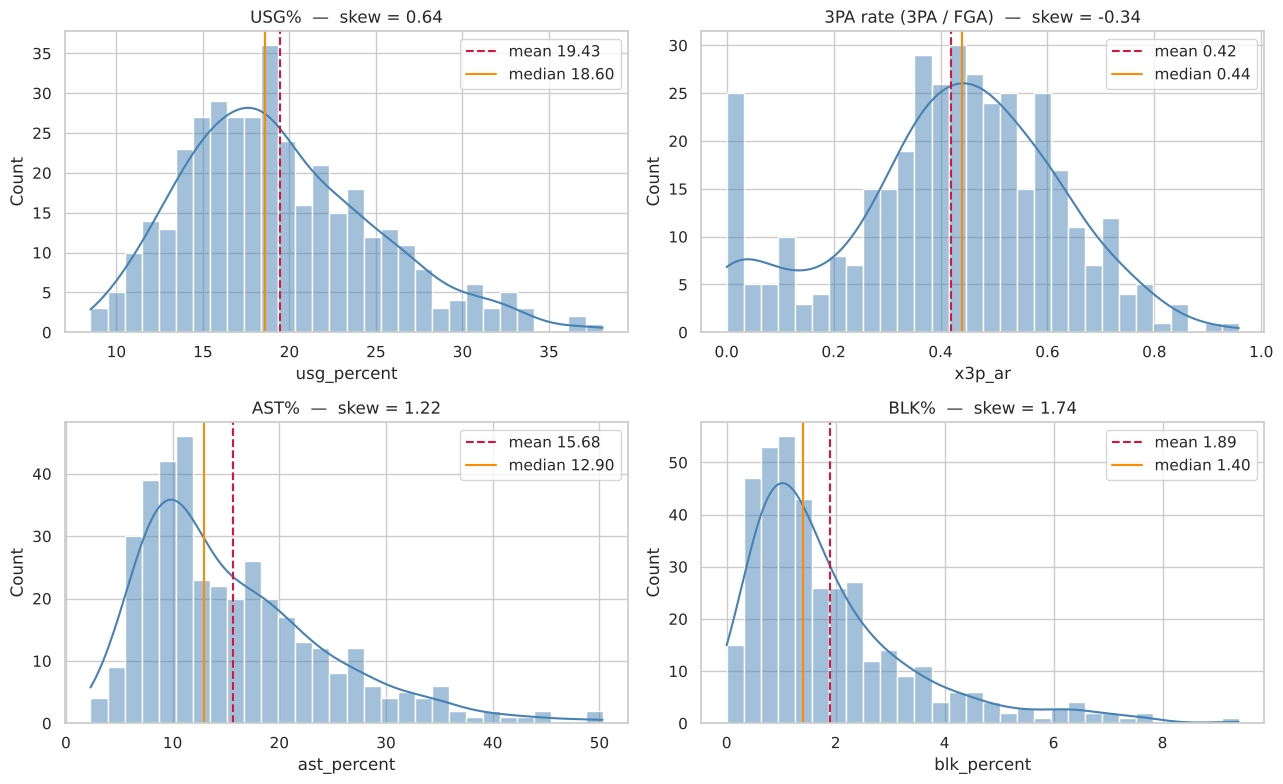

In [10]:
four = {'usg_percent': 'USG%', 'x3p_ar': '3PA rate (3PA / FGA)', 'ast_percent': 'AST%', 'blk_percent': 'BLK%'}

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for a, (col, label) in zip(ax.ravel(), four.items()):
    x = nba[col]
    sns.histplot(x, bins=30, kde=True, ax=a, color='steelblue', edgecolor='white')
    a.axvline(x.mean(), color='crimson', ls='--', label=f'mean {x.mean():.2f}')
    a.axvline(x.median(), color='darkorange', ls='-', label=f'median {x.median():.2f}')
    a.set_title(f'{label}  —  skew = {skew(x):.2f}'); a.legend()
plt.tight_layout(); plt.show()

**Reading the four histograms**
- **USG%**: mildly right-skewed (skew ≈ 0.6). Most players use 14–22% of plays, with a thin tail of high-usage
  stars (Dončić 38.1, Antetokounmpo 37.0, Brown 36.2). Close enough to normal that `StandardScaler` would be acceptable.
- **3PA rate**: the only *left*-skewed feature of the four (≈ −0.3) and **bounded in [0, 1]**. It is bimodal: a
  spike of 29 non-shooting bigs below 0.05, then a broad hump around 0.3–0.6, with only 6 pure spot-up shooters above
  0.8. The spike at zero is an archetype signal in itself (the rim-running big).
- **AST%**: clearly right-skewed (≈ 1.2). Most players assist on 8–18% of teammates' baskets, while primary
  ball-handlers reach 30–50%.
- **BLK%**: the most skewed (≈ 1.7). Most players sit at 0–2%, with a long tail of rim protectors up to about 9%.

---

**Goal.** Extend the skewness check from four features to the **full list of 23 candidate style features**, and
measure how well a Yeo-Johnson transform corrects each one.

**Why it matters here.** Four features could be a lucky sample; the scaling decision must hold for the whole feature
set. A rule of thumb is that |skew| > 1 indicates a strongly asymmetric distribution.

**What to look for.** How many features exceed |skew| > 1, *which kind* of features they are, and the
post-transform skew in the second column (values near 0 mean the transform succeeded).

In [11]:
candidates = ['usg_percent', 'ast_percent', 'tov_percent', 'orb_percent', 'drb_percent', 'trb_percent',
              'stl_percent', 'blk_percent', 'x3p_ar', 'f_tr', 'avg_dist_fga',
              'percent_fga_from_x0_3_range', 'percent_fga_from_x3_10_range', 'percent_fga_from_x10_16_range',
              'percent_fga_from_x16_3p_range', 'percent_fga_from_x3p_range', 'percent_dunks_of_fga',
              'percent_assisted_x2p_fg', 'pts_per_100_poss', 'fta_per_100_poss', 'ast_per_100_poss',
              'blk_per_100_poss', 'trb_per_100_poss']

pt = PowerTransformer(method='yeo-johnson', standardize=True)
transformed = pd.DataFrame(pt.fit_transform(nba[candidates]), columns=candidates)

sk = pd.DataFrame({'skew (raw)': nba[candidates].apply(skew),
                   'skew (Yeo-Johnson)': transformed.apply(skew)}).round(2)
sk['|raw| > 1 ?'] = np.where(sk['skew (raw)'].abs() > 1, 'yes', '')
sk.sort_values('skew (raw)', key=abs, ascending=False)

,skew (raw),skew (Yeo-Johnson),|raw| > 1 ?
percent_dunks_of_fga,2.44,0.40,yes
blk_per_100_poss,1.78,0.09,yes
blk_percent,1.74,0.05,yes
percent_fga_from_x16_3p_range,1.74,0.25,yes
orb_percent,1.64,0.03,yes
percent_fga_from_x0_3_range,1.47,0.07,yes
f_tr,1.35,0.01,yes
fta_per_100_poss,1.24,-0.00,yes
ast_percent,1.22,0.00,yes
trb_per_100_poss,1.09,0.03,yes


**Goal.** Compare the two scaling options visually on the same four features.

**Why it matters here.** Both scalers produce features with mean 0 and standard deviation 1, so summary statistics
alone cannot tell them apart; the difference is entirely in the *shape*, which is what drives distance-based
clustering.

**What to look for.** Top row (`StandardScaler`): the histograms are identical in shape to the raw ones above; only
the x-axis has changed. Bottom row (`PowerTransformer`): the long right tails of AST% and BLK% are pulled in and the
distributions become roughly symmetric.

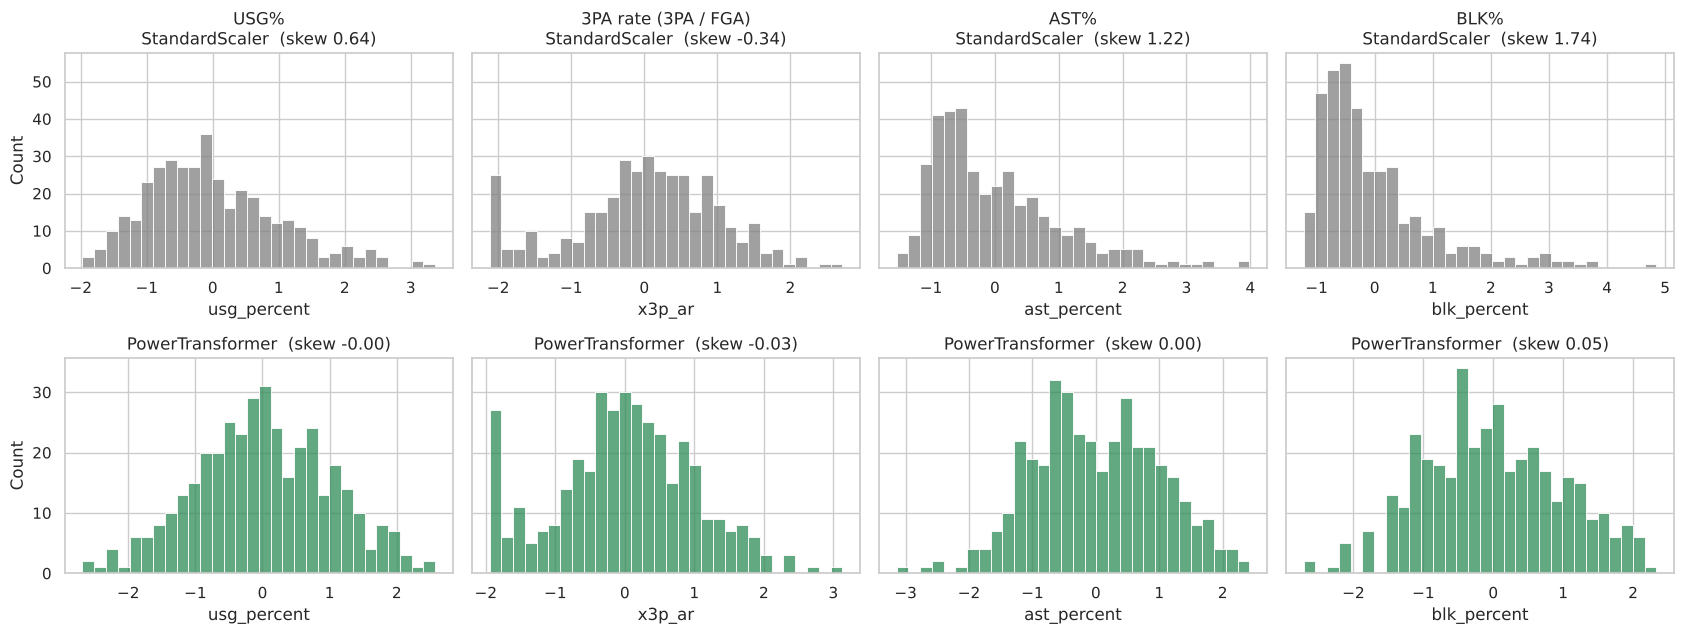

In [12]:
# side by side: StandardScaler keeps the shape, PowerTransformer reshapes it
std = pd.DataFrame(StandardScaler().fit_transform(nba[list(four)]), columns=list(four))
fig, ax = plt.subplots(2, 4, figsize=(17, 6.5), sharey='row')
for j, col in enumerate(four):
    sns.histplot(std[col], bins=30, ax=ax[0, j], color='grey')
    ax[0, j].set_title(f'{four[col]}\nStandardScaler  (skew {skew(std[col]):.2f})')
    sns.histplot(transformed[col], bins=30, ax=ax[1, j], color='seagreen')
    ax[1, j].set_title(f'PowerTransformer  (skew {skew(transformed[col]):.2f})')
plt.tight_layout(); plt.show()

### Findings: Distributions & scaling
- **13 of the 23 candidate features have |skew| > 1**: dunk share, BLK%, ORB%, rim-shot share, free-throw rate,
  AST%, TRB% and others. These are exactly the **specialist** stats (rim protection, offensive rebounding,
  playmaking, getting to the line) that should *define* archetypes, so it is important they are not dominated by a
  handful of extreme players.
- **Yeo-Johnson brings 22 of 23 features to |skew| < 0.3.** The exception is dunk share (0.40), a zero-inflated
  feature (many players have almost no dunks) that no monotone transform fully fixes.
- `PowerTransformer(standardize=True)` also returns mean 0 / std 1, so it *replaces* `StandardScaler` rather than
  being stacked on top of it.

**Scaling recommendation**
- **Default for clustering and PCA: `PowerTransformer(method='yeo-johnson')`** on all selected features.
- **Keep a `StandardScaler` version as a sensitivity check.** If clusters are stable under both, they are not an
  artefact of the transform.
- **For anomaly detection, prefer the less compressed (`StandardScaler`) version.** The power transform deliberately
  pulls extreme players toward the centre, and those extreme players are what Isolation Forest / LOF are meant to find.

---
## 5. Correlation Analysis & Redundant Feature Groups

**Goal.** Identify features that carry the same information, so the final feature matrix contains each concept once.

**Why it matters here.** In clustering, redundancy is not harmless. If three rebounding features are included, the
"rebounding" concept is effectively **counted three times** in the Euclidean distance, silently up-weighting it
relative to every other skill. In PCA, redundant groups inflate the leading components and make the loadings harder to
interpret. Removing redundancy is therefore a form of *feature weighting*, and it should be a deliberate choice.

### 5a. Per-game vs. per-100 possessions

**Goal.** The dataset offers the same box-score stats in three forms (per game, per 100 possessions, season totals).
Choose the one that best isolates *role* from *playing time*.

**Why it matters here.** A per-game number mixes two things: *what a player does when on the floor* and *how long the
player is on the floor*. A bench centre playing 15 minutes and a starter playing 32 minutes may rebound at exactly the
same rate, but their per-game rebounds differ by a factor of two. Per-100-possession stats normalise by opportunity
(and also remove differences in team pace), so the same role produces similar numbers regardless of minutes.

**What to look for.** For each stat: column 2 vs. column 3. Normalisation works if correlation with minutes per game
drops substantially when moving from per-game to per-100.

In [13]:
stats = ['pts', 'trb', 'ast', 'stl', 'blk', 'tov', 'fga', 'x3pa', 'fta']
rate_check = pd.DataFrame({
    'corr(per-game, per-100)':        [nba[f'{s}_per_game'].corr(nba[f'{s}_per_100_poss']) for s in stats],
    'corr(per-game, minutes/game)':   [nba[f'{s}_per_game'].corr(nba['mp_per_game']) for s in stats],
    'corr(per-100, minutes/game)':    [nba[f'{s}_per_100_poss'].corr(nba['mp_per_game']) for s in stats],
}, index=stats).round(2)
rate_check

,"corr(per-game, per-100)","corr(per-game, minutes/game)","corr(per-100, minutes/game)"
pts,0.91,0.86,0.59
trb,0.81,0.52,-0.03
ast,0.90,0.65,0.33
stl,0.74,0.61,-0.04
blk,0.90,0.25,-0.09
tov,0.87,0.72,0.33
fga,0.87,0.86,0.54
x3pa,0.87,0.58,0.15
fta,0.95,0.70,0.49


**Findings.** Per-game stats correlate with **minutes per game** at 0.25–0.86. Per-100 stats remove most of it: for
role stats (rebounds, steals, blocks, 3PA) the correlation with minutes drops to roughly 0. It stays around 0.5–0.6
only for scoring volume (PTS, FGA, FTA), because coaches give more minutes to players who score. That remaining link
is real basketball signal, not a playing-time artefact.
**Decision: use per-100 and %-based advanced stats; drop per-game and totals from the clustering matrix.**

### 5b. Correlation heatmap of candidate style features

**Goal.** Visualise pairwise Pearson correlations among the 23 candidate features (all 127 columns would be
unreadable).

**Why it matters here.** Some redundancy is definitional (a stat in two different units), and some is basketball
logic (players who take many shots at the rim also dunk a lot). Both kinds need to be found before PCA and clustering.

**What to look for.** Dark red / dark blue cells (|r| close to 1) away from the diagonal, and *blocks* of mutually
correlated features, which indicate a single underlying concept.

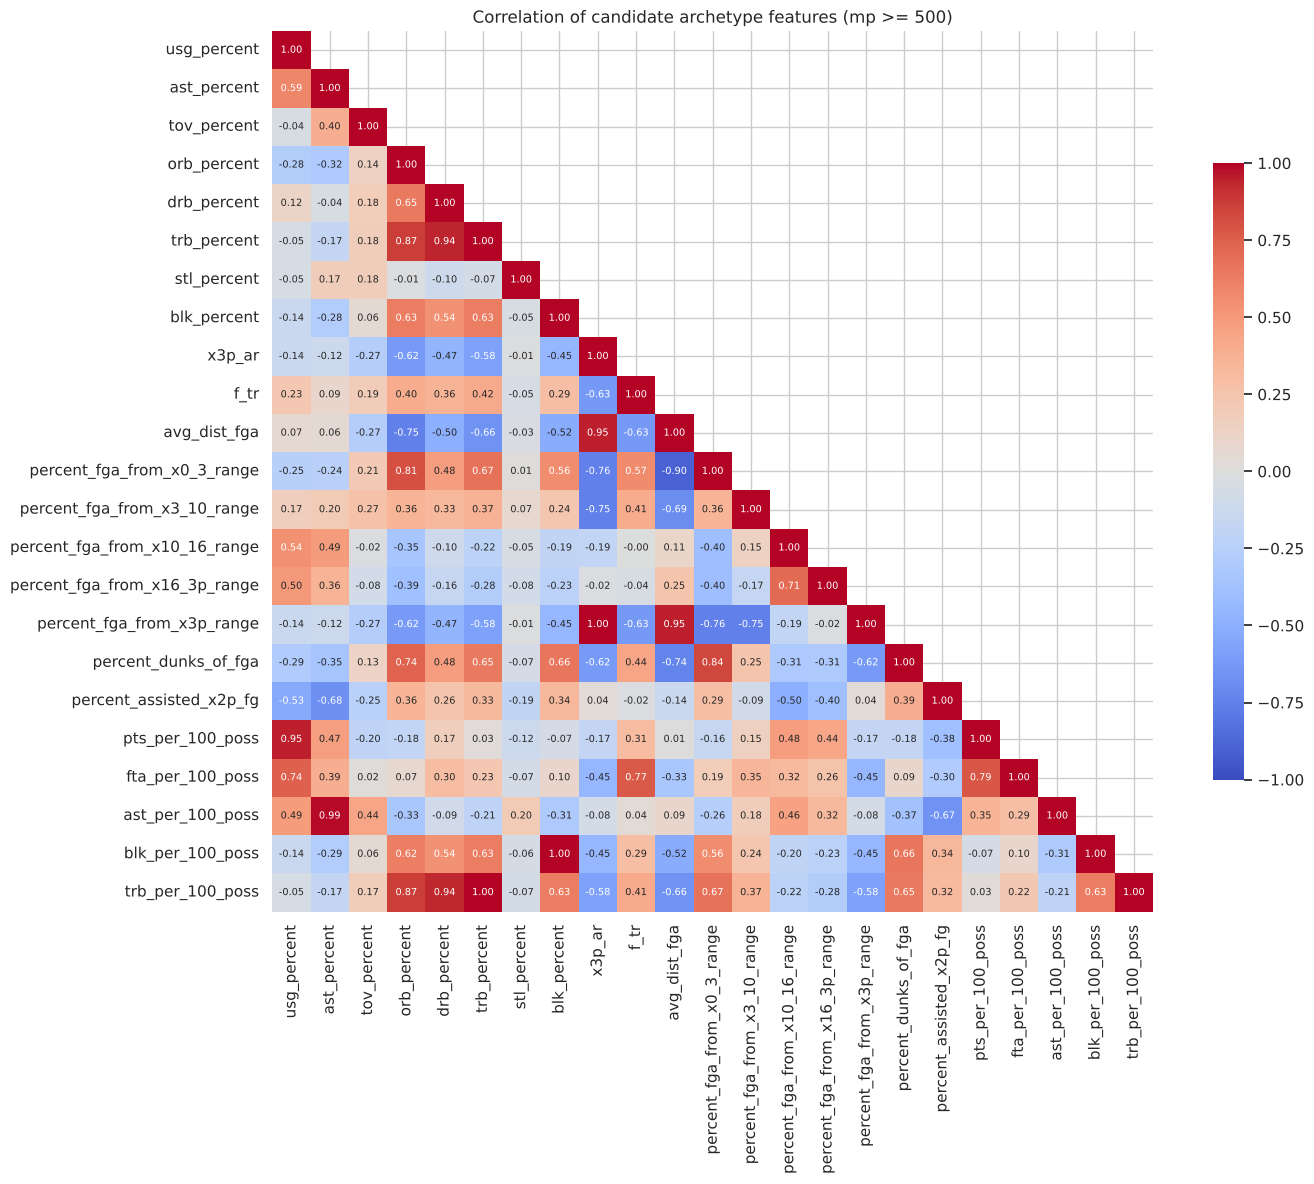

In [14]:
corr = nba[candidates].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(15, 12))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', annot_kws={'size': 7},
            cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.7})
plt.title('Correlation of candidate archetype features (mp >= 500)')
plt.tight_layout(); plt.show()

**Goal.** Turn the heatmap into an explicit, sorted list of highly correlated pairs (|r| ≥ 0.8), so redundancy
decisions are based on numbers rather than on reading colours.

**What to look for.** Pairs with r ≈ 1 (the same measurement in two forms: keep exactly one) versus pairs with
r ≈ 0.8–0.9 (related but distinct concepts: keep one or both, depending on basketball meaning).

In [15]:
pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
             .rename('r').reset_index().rename(columns={'level_0': 'feature A', 'level_1': 'feature B'}))
pairs['|r|'] = pairs['r'].abs()
top = pairs.sort_values('|r|', ascending=False).query('`|r|` >= 0.8').round(3)
print(f'{len(top)} pairs with |r| >= 0.8:')
top.reset_index(drop=True)

14 pairs with |r| >= 0.8:


,feature A,feature B,r,|r|
0,x3p_ar,percent_fga_from_x3p_range,1.000,1.000
1,trb_percent,trb_per_100_poss,0.999,0.999
2,blk_percent,blk_per_100_poss,0.997,0.997
3,ast_percent,ast_per_100_poss,0.985,0.985
4,x3p_ar,avg_dist_fga,0.949,0.949
5,avg_dist_fga,percent_fga_from_x3p_range,0.949,0.949
6,usg_percent,pts_per_100_poss,0.948,0.948
7,drb_percent,trb_percent,0.938,0.938
8,drb_percent,trb_per_100_poss,0.936,0.936
9,avg_dist_fga,percent_fga_from_x0_3_range,-0.903,0.903


### Findings: Redundant groups (one representative each)

There are **14 pairs with |r| ≥ 0.8**, and they collapse into a small number of concepts:

| Group | Members (r) | Keep | Reasoning |
|---|---|---|---|
| 3-point volume | `x3p_ar` = `percent_fga_from_x3p_range` (1.00), `avg_dist_fga` (0.95) | `x3p_ar` | Identical definitions; average distance is a summary of the zone shares |
| Rebounding | `trb_percent` ≈ `trb_per_100_poss` (1.00), ≈ `drb_percent` (0.94), ≈ `orb_percent` (0.87) | `orb_percent` + `drb_percent` | TRB% is just their combination. ORB vs. DRB are different jobs (crashing the offensive glass vs. finishing defensive possessions), and they correlate only 0.65 with each other |
| Shot-blocking | `blk_percent` ≈ `blk_per_100_poss` (1.00) | `blk_percent` | Same measurement, two units |
| Playmaking | `ast_percent` ≈ `ast_per_100_poss` (0.99) | `ast_percent` | Same measurement, two units |
| Scoring load | `usg_percent` ≈ `pts_per_100_poss` (0.95) | `usg_percent` | Usage is the role (how many plays a player finishes); points = role × efficiency |
| Paint / rim | `percent_fga_from_x0_3_range`, `percent_dunks_of_fga` (0.84), (−) `avg_dist_fga` (−0.90) | `percent_fga_from_x0_3_range` | Dunks are a subset of rim attempts |
| Free throws | `f_tr`, `fta_per_100_poss` (0.77, just under the cut-off) | `f_tr` | Rate per shot is a cleaner style measure than volume |

**Compositional constraint.** The five zone shares (0–3 ft, 3–10, 10–16, 16 ft to the arc, 3P) **sum to 1 for every
player**, so any one of them is a linear combination of the other four. Note that `x3p_ar` *is* the 3P share, so
keeping `x3p_ar` alongside all four two-point zones would still be perfectly collinear: at least one zone has to be
dropped or merged. The feature-selection notebook resolves this by merging the two mid-range zones, leaving the
3–10 ft zone implicit, and confirming the result with a variance inflation factor (VIF) check.

---
## 6. Style Stats by Listed Position

**Goal.** Compare the distribution of six style features across the five listed positions.

**Why it matters here.** This is the first direct test of the project's premise. If positions were still an accurate
description of on-court roles, each position would occupy its own range on each stat, with little overlap. If the
league has become "positionless", the boxes will overlap heavily and differences will show up only at the extremes
(e.g. centres).

**How to read the plot.** Each box spans the middle 50% of players at that position (interquartile range), the line
inside is the median, and whiskers extend to 1.5×IQR. Individual players are overlaid as dots, so cluster structure
*within* a position is visible too.

**What to look for.**
- Boxes at roughly the same height across several positions mean the position label does not predict that skill.
- An unusually tall box or a dot cloud with two clumps inside one position suggests that label hides several
  distinct roles.
- A steady staircase from PG to C suggests a continuum rather than discrete categories.

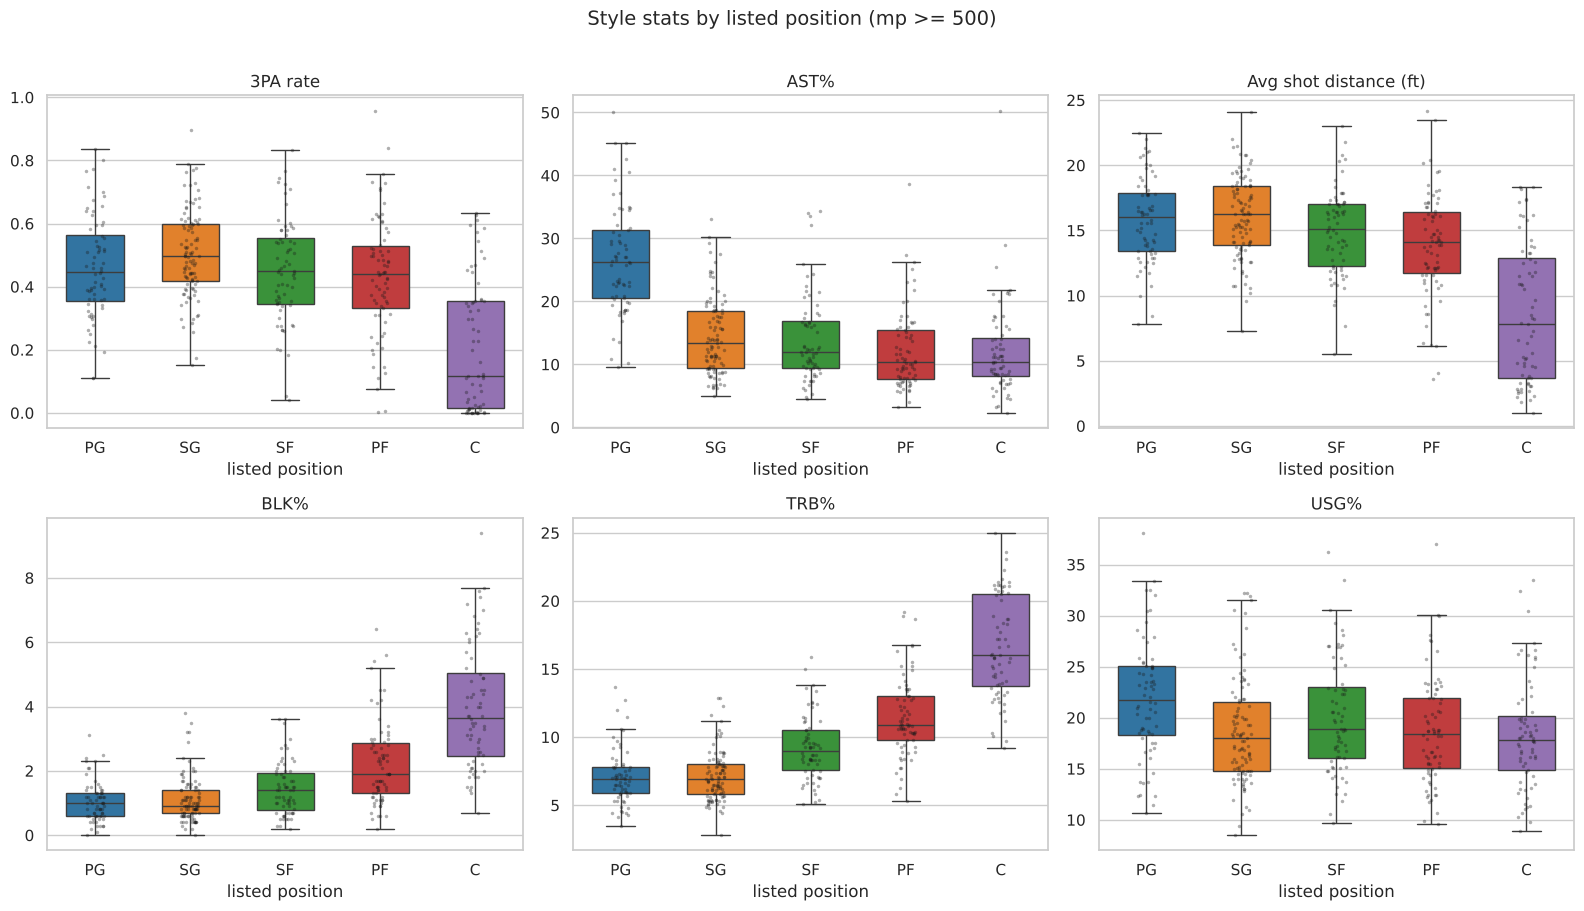

In [16]:
box_feats = {'x3p_ar': '3PA rate', 'ast_percent': 'AST%', 'avg_dist_fga': 'Avg shot distance (ft)',
             'blk_percent': 'BLK%', 'trb_percent': 'TRB%', 'usg_percent': 'USG%'}
palette = dict(zip(POS_ORDER, sns.color_palette('tab10', 5)))

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, (col, label) in zip(ax.ravel(), box_feats.items()):
    sns.boxplot(data=nba, x='pos', y=col, order=POS_ORDER, hue='pos', palette=palette, legend=False,
                ax=a, width=0.6, fliersize=0)
    sns.stripplot(data=nba, x='pos', y=col, order=POS_ORDER, color='k', size=2.5, alpha=0.35, ax=a)
    a.set(title=label, xlabel='listed position', ylabel='')
plt.suptitle('Style stats by listed position (mp >= 500)', y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

**Goal.** Put a single number on "how much does listed position explain this stat?"

**Method: η² (eta-squared).** The total variance of a feature is split into the part *between* position groups
(how far each position's mean is from the overall mean) and the part *within* groups (how spread out players are
inside the same position):

$$\eta^2 = \frac{\sum_{g} n_g\,(\bar{x}_g - \bar{x})^2}{\sum_{i} (x_i - \bar{x})^2}$$

η² is the R² of a regression of the feature on position dummy variables. **η² = 1** means position fully determines
the stat; **η² = 0** means knowing the position tells you nothing about it.

**What to look for.** Which stats position explains well (high η²: largely the "big-man" stats) and which it barely
explains (low η²). Low-η² features are exactly the dimensions on which a data-driven grouping could add information
beyond the labels.

In [17]:
def eta_squared(frame, col, group='pos'):
    grand = frame[col].mean()
    between = frame.groupby(group)[col].apply(lambda g: len(g) * (g.mean() - grand) ** 2).sum()
    return between / ((frame[col] - grand) ** 2).sum()

summary = nba.groupby('pos')[list(box_feats)].median().loc[POS_ORDER].T
summary.columns = [f'median {p}' for p in POS_ORDER]
summary['eta² (pos)'] = [eta_squared(nba, c) for c in box_feats]
summary.index = [box_feats[c] for c in summary.index]
summary.round(3)

,median PG,median SG,median SF,median PF,median C,eta² (pos)
3PA rate,0.446,0.497,0.448,0.442,0.118,0.267
AST%,26.200,13.400,11.950,10.350,10.400,0.356
Avg shot distance (ft),16.000,16.300,15.150,14.100,7.850,0.332
BLK%,1.000,0.900,1.400,1.900,3.650,0.464
TRB%,6.900,6.900,9.000,10.900,16.000,0.641
USG%,21.750,18.000,18.900,18.400,17.850,0.053


**Goal.** Compare each player's **listed** position with the position at which the player **actually logged the most
minutes**, according to play-by-play data.

**Why it matters here.** The listed position is a roster label, set once and rarely updated. The play-by-play
estimates record how coaches actually used each player, lineup by lineup, across the season. Disagreement between
the two is direct evidence that labels lag behind on-court usage, and it gives us a second validation target for the
clustering stage.

**What to look for.** The diagonal of the matrix (agreement) versus off-diagonal cells (disagreement), and especially
*where* the disagreements fall: between neighbouring positions (a continuum) or between distant ones (labels that are
plainly wrong).

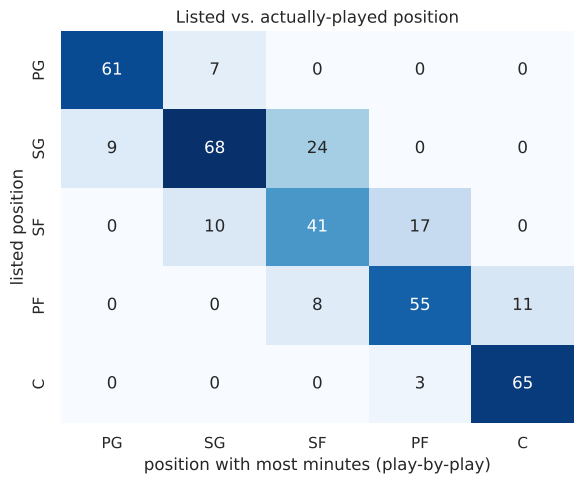

listed position = most-played position for 77% of players


In [18]:
pbp_cols = ['pg_percent', 'sg_percent', 'sf_percent', 'pf_percent', 'c_percent']
nba['pos_played'] = nba[pbp_cols].idxmax(axis=1).str.split('_').str[0].str.upper()
ct = pd.crosstab(nba['pos'], nba['pos_played']).loc[POS_ORDER, POS_ORDER]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
ax.set(xlabel='position with most minutes (play-by-play)', ylabel='listed position',
       title='Listed vs. actually-played position')
plt.tight_layout(); plt.show()
print(f"listed position = most-played position for {np.trace(ct.values) / ct.values.sum():.0%} of players")

### Findings: Evidence of positional blurring
- **Only the C category is truly distinct.** Centres stand apart on every interior stat (3PA rate ≈ 0.12, shot
  distance ≈ 8 ft, BLK% ≈ 3.7, TRB% ≈ 16). That is what drives most of the η² values.
- **…but the C box is itself split.** Its 3PA-rate box runs from 0 to about 0.35 and its shot-distance box from about
  4 to 13 ft: "C" already holds at least two archetypes (the zero-three rim-runner vs. the stretch / hub big).
- **SG, SF and PF are nearly indistinguishable on spacing**: 3PA-rate medians of 0.50 / 0.45 / 0.44 and shot-distance
  medians of 16.3 / 15.2 / 14.1 ft. The "stretch four" is now the default power forward, not the exception.
- **AST% separates PGs from everyone else, but SG ≈ SF ≈ PF ≈ C** (medians 10–13%). The PG and SG boxes also overlap
  widely: many listed SGs are lead creators, and many listed PGs play off the ball.
- **Rebounding is a gradient, not five classes**: TRB% medians climb steadily, PG 6.9 → SG 6.9 → SF 9.0 → PF 10.9 →
  C 16.0 (η² = 0.64, the highest), with heavily overlapping neighbouring boxes.
- **USG% has η² = 0.05**: how much of the offense a player finishes is essentially independent of position. This is
  exactly the dimension a five-position label cannot express (high-usage centres and low-usage point guards are both
  common).
- **Coaches don't follow the labels either**: for **23% of players** the most-played slot differs from the listed one,
  and the disagreements fall *only* between neighbouring positions (PG↔SG, SG↔SF, SF↔PF, PF↔C).

**Implication for modelling.** Positions behave like points on a **continuum** rather than five discrete classes.
That favours **soft-membership models (GMM)**, which can say "60% wing, 40% big", and it suggests the most
interesting archetypes will be defined by the low-η² dimensions (usage, creation) that labels ignore.

---
## 7. Summary & Decisions for the Feature Selection & Scaling Stage

| Area | Finding | Decision |
|---|---|---|
| Sample | 35% of players have < 500 MP; their rate stats are extreme and unreliable | Keep `mp >= 500` → **379 players** |
| Missing values | All structural (0 attempts → undefined %); median imputation would invent 35% shooters | No statistical imputation. Exclude make-% columns; frequency columns are complete; `percent_corner_3s_of_3pa` → 0 if used |
| Per-game vs. per-100 | Per-game stats track minutes (r up to 0.86); per-100 role stats do not (r ≈ 0) | Use per-100 / %-based advanced stats only |
| Redundancy | 14 pairs with \|r\| ≥ 0.8 across rebounding, 3P volume, AST, BLK and usage groups; zone shares sum to 1 | One representative per group (about 12–14 features) |
| Skewness | 13 of 23 candidates have \|skew\| > 1, mostly specialist stats | `PowerTransformer(yeo-johnson)` by default; `StandardScaler` as a sensitivity check and for anomaly detection |
| Validation targets | Listed `pos` is coarse; C is the only distinct label; 23% of players play mostly at another slot | Use both `pos` and play-by-play `pos_played` for ARI |

### Export

**Goal.** Save the filtered population (379 players, including the new `pos_played` column) so the next notebook
starts from exactly the data analysed here, with no risk of re-applying the filter differently.

In [19]:
out = DATA / 'processed'
out.mkdir(exist_ok=True)
nba.to_csv(out / 'nba_2025_26_mp500.csv', index=False)
print('saved', out / 'nba_2025_26_mp500.csv', nba.shape)

saved ../data/processed/nba_2025_26_mp500.csv (379, 128)
